# 3.1 Linear Regression

In [14]:
%matplotlib inline
import math
import time
import numpy as np
import torch
from d2l import torch as d2l

### 3.1.1 Basics

Assume linearity between relationship between features $x$ and target $y$ i.e. $E[Y | X = x]$ can be expressed as a weighted up of features $x$. We also impose assumoption fo well behaved noise, say a Gaussian distribution. Note we will use the notatinon $x^{(i)}$ for the ith sample and $x_j^{(i)}$ for the jth coordinate of the ith sample. 

3.1.1.1 Model

By the weighted sum of features $x$ above, we refer to something like: $$\text{price} = w_{area}\cdot \text{area} + w_{age} \cdot \text{age} + b$$. Note that the equation above is an _affine transformation_ of input features, as in that it is a linear transformatino of features via a weighted sum combined with translation with the bias. Related to affine subsets from LADR ig. 

In situations with a few features, it is common to write out models long form like above, but tpyically in ML, we are working with high-dimensional dataset so it is more convinenent to use compact linear algebra notation where $\hat{y}$ means our prediction from $d$ features: $$\hat{y} = w_1 x_1 + \cdots + w_d x_d + b$$ and collecting all features and weights into a vector s.t. $x, w \in \mathbb{R}^d$ do er can compactly write this as: $$\hat{y} = w^T x + b$$ where x refers to a the features of a SINGLE example. Often, it may be convient to refer to features of entire dataset of $n$ examples via _design matrix_ $X\in \mathbb{R}^{n \times d}$, where each row corresponds to an example and each column corresponds to the features, and thus we can write it as: $$\hat{y} = Xw + b$$ (notice no transpose) where broadcasting is applied during the summation (for the bias vector to match Xw). 

3.1.1.2 Loss Function

Usually quanity some distance between real and predicted values of the target. Usually, it will be a non-negative number where s ameller value is better and perfect predictions correspond to losses of 0. In linear regression, we use the mean-squared error (MSE) frequently, where it is written as: $$ l^{i}(w, b) = \frac{1}{2} \left(\hat{y}^{(i)} - y^{(i)} \right)^2$$ where the $\frac{1}{2}$ is just for convinence when we take derivative for backprop, it will cancel out. 

The quality of our model on entire dataset of $n$ examples will be caluculated by averageing/summing the losses on the entire training set: $$L(w, b)=\frac{1}{n}\sum_{i=1}^{n} l^{(i)}(w, b)=\frac{1}{n}\sum_{i=1}^{n}\frac{1}{2}\left(w^{\top}x^{(i)} + b - y^{(i)}\right)^2$$

Where we seek $(w^*, b^*)$ s.t. we minimize the total loss across all training examples:$$w^{*},b^{*}=\operatorname*{argmin}_{w,b}L(w,b)$$

3.1.1.3 Analytical Solution

Unlike most ML models, linear regression gives us a analytical solution to its optimization. 

First, we absorb the bias $b$ into the parameter $w$ and also append a column of all 1's to the design matrix $X$. Our overall goal is to minimze $||y-Xw||^2$. As long as the design matrix $X$ has full rank (i.e. no feature is linearly dependent on the others), then there will be just one critical point on loss surface that minimizes the loss over the entire domain. We calculate this point by taking the derivative of the loss w.r.t. to $w$ and then set it equatl to 0 to get: $$\partial_{\mathbf{w}} \|\mathbf{y} - \mathbf{X}\mathbf{w}\|^2 = 2 \mathbf{X}^\top (\mathbf{X}\mathbf{w} - \mathbf{y}) = 0 \textrm{ and hence } \mathbf{X}^\top \mathbf{y} = \mathbf{X}^\top \mathbf{X}\mathbf{w}$$ where our solution below for $w^*$ will only be unique if the matrix $X^T X$ is invertible (i.e. columsn of design matrix are linearly independent) $$\mathbf{w}^* = (\mathbf{X}^\top \mathbf{X})^{-1}\mathbf{X}^\top \mathbf{y}$$

3.1.1.4 Minibatch Stochastic Gradient Descent

Useful when dataset is large (many training examples) and cannot get an analytical solution to minimize the loss (most ML settings). 

Processors are a lot faster at multiply and adding numbers than they are moving data from main memory to processor cache. Thus, it is significantly more efficient to matrix-vector opertations than vector-vector operations. This motivates the use of many training examples in a batch, rather than each training example one at a time. Also, say if we are using batchnorm, that only works wiht muliple training examples (but that has other issues at say inference since that may be only 1 at a time)

On each iteration _t_, randomly sample a minibatch $\Beta_t$ consisting of a fixeed number of training examples $|\Beta|$ of training examples. Then, compute the derivative of the average loss of the minimatch w.r.t. model parameters. Then, multiply said gradient term by learning rate $\eta$ and subtract from current parameters values (follow negative gradient direction since we want to minimize loss and gradient points in directino of maximum positive change). $$(\mathbf{w}, b) \leftarrow (\mathbf{w}, b) - \frac{\eta}{|\mathcal{B}|} \sum_{i \in \mathcal{B}_t} \partial_{(\mathbf{w}, b)} l^{(i)}(\mathbf{w}, b)$$


Stuff like learning rate and batch sizes are called _hyperparameters_. At the end, the quality of our parameters can be evaluated on the _validation set_. Note that we can rarely find the global minimum in ML but just a sufficiently good set of parameters that produces a low loss. 

3.1.1.5 Predictions

Sometimes, running ML models is called "inference". However, this can be misleading so the authors will use the term "prediction" to refer to running ML models. 

### 3.1.2 Vectorization for Speed
Vectorize for speed. See below for elementwise sum example

In [15]:
import time
n = 10000
a = torch.ones(n)
b = torch.ones(n)

In [16]:
# for-loop Method for elementwise sum
c = torch.zeros(n)
t = time.perf_counter()
for i in range(n):
    c[i] = a[i] + b[i]
f'{time.perf_counter() - t:.7f} sec'

'0.0499594 sec'

In [17]:
# Vectorized Method for elementwise sum
t = time.perf_counter()
d = a + b
f'{time.perf_counter() - t:.7f} sec'

'0.0001304 sec'

### 3.1.3 Normal Distribution and Squared Loss

Recall how normal distributions work and the effect/meaning of the parameters $\mu$ and $\sigma$. $$p(x) = \frac{1}{\sqrt{2 \pi \sigma^2}} \exp\left(-\frac{1}{2 \sigma^2} (x - \mu)^2\right)$$

According to the _Principle of Maximum Likelihood_, the best set of parametesr $w$, $b$ are the parameters that maximize the likelihood of the entire dataset, whhich can be written as: $$P(\mathbf{y} \mid \mathbf{X}) = \prod_{i=1}^{n} p(y^{(i)} \mid \mathbf{x}^{(i)})$$

Since it can be difficult to maximise a product of exponentials, we often deal with their logarithims instead. And for historical reasons, we are often interested in minimization. Therefore, we can write: $$-\log P(\mathbf{y} \mid \mathbf{X}) = \sum_{i=1}^{n} \frac{1}{2} \log(2 \pi \sigma^2) + \frac{1}{2\sigma^2} \left(y^{(i)} - \mathbf{w}^\top \mathbf{x}^{(i)} - b\right)^2$$

Notice that the 2nd term in the summation is equal to the squared loss term with a factor of $\frac{1}{\sigma^2}$ out in front. Minimizing the mean squared error is equivalent to the maximum likelihood estimation of the lienar model under assumoption of gaussian additive noise. 

In [18]:
# Defining a normal distributio function
def normal(x, mu, sigma):
    p = 1 / math.sqrt(2 * math.pi * sigma**2)
    return p * np.exp(-0.5 * (x - mu)**2 / sigma**2)

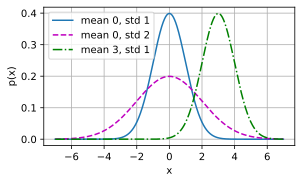

In [19]:
# Visualizing the normal distribution 

# Use NumPy again for visualization
x = np.arange(-7, 7, 0.01)

# Mean and standard deviation pairs
params = [(0, 1), (0, 2), (3, 1)]
d2l.plot(x, [normal(x, mu, sigma) for mu, sigma in params], xlabel='x',
         ylabel='p(x)', figsize=(4.5, 2.5),
         legend=[f'mean {mu}, std {sigma}' for mu, sigma in params])

### 3.1.4 Linear Regression as a Neural Network

In the context of linear regression, there are many inputs neurons, and a single output neuron, a scalar we are trying to predict. 

Stuff about biological neurons, synaptic weights, activiation biases, etc.

Although airplanes may have been inspired by birds, ornithology has not been a primary driver of innovation in aernoatucs. Likesise, in deep/machine learning inspirations/innovations have come from a wide varierrty of fields like mathematics, linguistics, psychology, statistics, computer science, and many other fields

### 3.1.5 Summary
Skip

### 3.1.6 Exercises

1. Assume that we have some data $x_1, \ldots, x_n \in \mathbb{R}$. Our goal is to find a constant $b$ such that $\sum_i (x_i - b)^2$ is minimized.
   1. Find an analytic solution for the optimal value of $b$.
   2. How does this problem and its solution relate to the normal distribution?
   3. What if we change the loss from $\sum_i (x_i - b)^2$ to $\sum_i |x_i-b|$? Can you find the optimal solution for $b$?
2. Prove that the affine functions that can be expressed by $\mathbf{x}^\top \mathbf{w} + b$ are equivalent to linear functions on $(\mathbf{x}, 1)$.
3. Assume that you want to find quadratic functions of $\mathbf{x}$, i.e., $f(\mathbf{x}) = b + \sum_i w_i x_i + \sum_{j \leq i} w_{ij} x_i x_j$. How would you formulate this in a deep network?
4. Recall that one of the conditions for the linear regression problem to be solvable was that the design matrix $\mathbf{X}^\top \mathbf{X}$ has full rank.
   1. What happens if this is not the case?
   2. How could you fix it? What happens if you add a small amount of coordinate-wise independent Gaussian noise to all entries of $\mathbf{X}$?
   3. What is the expected value of the design matrix $\mathbf{X}^\top \mathbf{X}$ in this case?
   4. What happens with stochastic gradient descent when $\mathbf{X}^\top \mathbf{X}$ does not have full rank?
5. Assume that the noise model governing the additive noise $\epsilon$ is the exponential distribution. That is, $p(\epsilon) = \frac{1}{2} \exp(-|\epsilon|)$.
   1. Write out the negative log-likelihood of the data under the model $-\log P(\mathbf{y} \mid \mathbf{X})$.
   2. Can you find a closed form solution?
   3. Suggest a minibatch stochastic gradient descent algorithm to solve this problem. What could possibly go wrong? Hint: what happens near the stationary point as we keep on updating the parameters? Can you fix this?
6. Assume that we want to design a neural network with two layers by composing two linear layers. That is, the output of the first layer becomes the input of the second layer. Why would such a naive composition not work?
7. What happens if you want to use regression for realistic price estimation of houses or stock prices?
   1. Show that the additive Gaussian noise assumption is not appropriate. Hint: can we have negative prices? What about fluctuations?
   2. Why would regression to the logarithm of the price be much better, i.e., $y = \log \textrm{price}$?
   3. What do you need to worry about when dealing with pennystock, i.e., stock with very low prices? Hint: can you trade at all possible prices? Why is this a bigger problem for cheap stock? For more information review the celebrated Black--Scholes model for option pricing.
8. Suppose we want to use regression to estimate the number of apples sold in a grocery store.
   1. What are the problems with a Gaussian additive noise model? Hint: you are selling apples, not oil.
   2. The Poisson distribution captures distributions over counts. It is given by $p(k \mid \lambda) = \lambda^k e^{-\lambda}/k!$. Here $\lambda$ is the rate function and $k$ is the number of events you see. Prove that $\lambda$ is the expected value of counts $k$
   3. Design a loss function associated with the Poisson distribution.
   4. Design a loss function for estimating $\log \lambda$ instead.

Exercise #1

To minimize $\sum_i (x_i - b)^2 $, take the derivative of it w.r.t. b and set it equatl to 0, and then solve for $b^*$. Doing so, we get: $$ -2 \sum_i^n (x_i - b^*)= 0$$ $$\sum_i^n x_i - nb^* = 0$$ $$b^* = \frac{1}{n} \sum_i^n x_i$$
So the optimal bias is the sample mean. 

The assumptions of gaussian noise and linearity between features and output, we can write the data generation proces as $x_i = b + \epsilon_i$ where $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$ and thus $x_i \sim \mathcal{N}(b, \sigma^2)$. Plugging in this into the maximum likelihood principle for x given b, we find: $$P(x_1,\ldots,x_n \mid b)=\prod_{i=1}^{n}\frac{1}{\sqrt{2\pi\sigma^2}}\exp\left(-\frac{(x_i-b)^2}{2\sigma^2}\right)$$ where maximizing the likelihood would correspond to the minimizatino of the term $\sum_i (x_i - b)^2$. The optimal b^* is the mean of the data i.e. most likely matches the mean of the gaussian distribution of the data generating process for our training st. 

If our loss changes from $\sum_i (x_i - b)^2$ to $\sum_i |x_i - b|$, our optimal solutino for $b^*$ would be calculated by summing of +1 if $b > x_i$ and -1 if $b < x_i$ for each iteration of the summation. Thus, our optimal $b^*$ for an L1 loss would just the median of the training set/examples. 


Exercise #2

We want to show that affine functions that can be written as $x^\top w + b$ are equivalent to linear functions on $(x, 1)$. Note that an affine function $x^\top w + b$ is not linear on $x$ because linearity means additivity and homogenity must be satisfied, but that forces $T(0) = 0$, which is not the case due to the bias term. 

However, in this case, we will defined the modified input vector and weight vector respectively as $ x' = \begin{bmatrix} x \\ 1 \end{bmatrix} $ and $ w' = \begin{bmatrix} w \\ b \end{bmatrix} $. Doing so will result in: $x'^\top w' = \begin{bmatrix} x^\top & 1 \end{bmatrix} \begin{bmatrix} w \\ b \end{bmatrix} = x^\top w + b$, which shows that $f(x) = x^\top w + b = x'^\top w'$, thus the affine functino is linear on $(x, 1)$. 

Exercise #3 

To formulate quadratic functions of $x$ in a deep network of linear components, one would to use the first "linear layer" with the raw inputs - have the weights for the raw inputs be the raw weights themselves. Then, for the 2nd lienar layer, one can use it with "standard" trainable weights.  

Exercise #4 
1. If $X^\top X$ is no longer full rank (i.e. linearly independent), we can no longer use: $$\mathbf{w}^* = (\mathbf{X}^\top \mathbf{X})^{-1}\mathbf{X}^\top \mathbf{y}$$
2. We could just reduce the redunaant (i.e. linearly dependent) components. Or, another possible fix hinted at in the question is by adding a small amount of coordinate-wise independent gaussian noise to all entries of $X$, since that would "break" the linear dependence and make it lineraly independent again, but since that is distorting the data itself (recall $X$ is the design matrix). 
3. The expected value of the design matrix $X^\top X$ in this case would be: $ \mathbb{E}[X'^\top X]$ where $X' = X + E$. Thus: $$ X'^\top X' = (X + E)^\top (X + E) = X^\top X + X^\top E + E^\top X + E^\top E$$ Notice, that the expectation operator of the middle two terms will be 0 because the expectation value of a gaussian distribution is 0, and the $X$ dosen't change this. Note that the $E^\top E$ does not become 0 under the expectation operator. Take a look at the alst term where we will consider an arbitary $(i, j)$ within $E^\top E \in \mathbb{R}^{d \times d}$, $(E^\top E)_{ij} = \sum_i^n E_{ki} E_{kj}$

First consider the diagonal terms: $$ (E^\top E)_{ii} = \sum_{i=1}^n E_{ki} E_{ki} = \sum_{i=1}^n E_{ki}^2 $$Recall that although the expectation value of a gaussian variable is 0, the expectation value of a gaussian variable squared is the variance. Recall: $\sigma^2 = Var(x) = \mathbb{E[x^2]} - \mathbb{E[x]}^2$. Therefore, $$ (E^\top E)_{ii} = \sum_{i=1}^n E_{ki} = \sum_{i=1}^n \sigma^2 = n \sigma^2 $$ so every diagonal slot has works out to be $n\sigma^2$. For the off-diagonal terms $(i\neq j)$, we can separate out the summand to $\mathbb{E}[E_{ki}] \mathbb{E}[E_{kj}]$, at which point we recall that we added "coordinate-wise indepdent gaussisn noise", so all the off-diagonal terms reduce to 0. 

Collecting all of our terms we get: $$\mathbb{E}[X'^T X'] = X^\top X + n\sigma^2 I$$
Takeaway: adding Gaussisn noise to design amtrix $X$ is equivalent to adding a diagonal variance term. 

For SGD, we should still be able to run it even if $X^\top X$ is not full rank, since it is a general-purpose algorithim that will converge (not nessacilty to global minimum or a unique solution) as long as learning rate/step-size is sufficiently small (so it miminc standard gradient descent) 

Exercise #5

Assume $p(\epsilon) = \frac{1}{2} \text{exp}(-|\epsilon|)$. To find the nll under that model, we first recall: $$P(\mathbf{y} \mid \mathbf{X}) = \prod_{i=1}^{n} p\left(y^{(i)} \mid \mathbf{x}^{(i)}\right)$$ 
Recall in the linear model $y^{(i)} = w^\top x^{(i)} + b + \epsilon^{(i)}$, wehich we can rewrite as: 

$$ \epsilon^{(i)} = y^{(i)} - w^\top x^{(i)} - b $$

which we substite into $p(\epsilon)$ to get: 

$$ p(y^{(i)}|x^{(i)}) = \frac{1}{2}\text{exp}(-|\epsilon^{(i)} = y^{(i)} - w^\top x^{(i)} - b|)$$

And thus all pairs $(x^{(i)}, y^{(i)})$ were drawn independently of each other, we can write down and substitute: 

$$ P(\mathbf{y} \mid \mathbf{X}) = \prod_{i=1}^{n} p(y^{(i)} \mid \mathbf{x}^{(i)}) = \prod_{i=1}^{n} \frac{1}{2}\text{exp}(-|\epsilon^{(i)} = y^{(i)} - w^\top x^{(i)} - b|)$$

Taking the negative-log of this, we get: 
$$ -\text{log} P(y|X) = n \text{log}(2) + \sum_{i=1}^n |y^{(i) - w^\top x^{(i)} - }b |$$
Since out the constant out in front is fixed, we see that based on the 2nd term, that this noise returns a L1 regression model (not MSE). 

Due to the absolute value, it is not differentiable at the point w.r.t. to its parameters, thus a closed-form solution in general (recall was possible with absolute distance error for $b^*$ earlier). 

A SGD algorithim for this error function can be defined as follow: 

Define the prediction and residual loss/error respectively:
$$\hat{y}^{(i)}=w^\top x^{(i)}+b$$
$$r^{(i)}=\hat{y}^{(i)}-y^{(i)}$$

Then the loss for one training example is: $\ell^{(i)}(w,b)=\left|r^{(i)}\right|$

For $r^{(i)}\neq 0$, the gradient with respect to $w$ is:

$$\nabla_w \ell^{(i)}=\operatorname{sign}(r^{(i)})x^{(i)}$$

The gradient with respect to $b$ is:

$$\nabla_b \ell^{(i)}=\operatorname{sign}(r^{(i)})$$

For a minibatch $\mathcal{B}$, the minibatch gradients are:

$$g_w=\frac{1}{|\mathcal{B}|}\sum_{i\in \mathcal{B}}\operatorname{sign}(\hat{y}^{(i)}-y^{(i)})x^{(i)}$$

$$g_b=\frac{1}{|\mathcal{B}|}\sum_{i\in \mathcal{B}}\operatorname{sign}(\hat{y}^{(i)}-y^{(i)})$$

Then SGD updates the parameters by:

$$w \leftarrow w-\eta g_w$$

$$b \leftarrow b-\eta g_b$$

Substituting in the minibatch gradients:

$$w \leftarrow w-\eta \frac{1}{|\mathcal{B}|}\sum_{i\in \mathcal{B}}\operatorname{sign}(\hat{y}^{(i)}-y^{(i)})x^{(i)}$$

$$b \leftarrow b-\eta \frac{1}{|\mathcal{B}|}\sum_{i\in \mathcal{B}}\operatorname{sign}(\hat{y}^{(i)}-y^{(i)})$$

Maybe a possible thing that can go wrong with this is that due to absolute value of the loss, its derivative is not smooth at a point where $r \approx 0$, and the derivative will bounce about the point, but not smoothly converge to it. Perhaps having a small step size will help with it, that way we are not subject to sign changes of the derivative as we close in on the point $r \approx 0$. 


Exercise #6

This naive composition will not work since two linear layers just blindly stacked on top of each other is mathematically equivalent to just a single linear layer (due to matrix multiplication properties). Do take advantage of more linear layers, one needs to introduce non-linearities, in this case at the output of the 1st linear layer and before the 2nd linear layer. 

Exercise #7
1. Gaussian noise assumoption is innapropriate for housing or stock prices due to the possible negative prices that are possible, since the gaussian distributin is not bound in any direction. This can be much more prominent of the std/variance is large w.r.t. the price itself. 
2. Regression to the lgoarithim of the price would be much better, because that forces non-negativty of the price itself
$$ y = \log(\text{price}) $$
3. When trading penny stocks, we now have to worry about discretizatino (assuming non-negative prices has been solved with regression to logarithim of the price), since prices are discretisized to fininte fraction of a penny, but that could be number w.r.t. to the stock price of a penny stock itself, especially under a log-price setup. 

Exercise #8

https://d2l.ai/chapter_linear-regression/linear-regression.html#exercises

# SKIPPING FOR NOW. NEXT SECTION LOOKS MUCH MORE INTERESTING

# 3.2 Object-Oriented Design for Implementation

Note - most code in this book will focus on _Module_ and _DataModule_. _Trainer_ will only be discussed when GPUs, CPUs, parallel training, and optimization algos come up later

At a high level we wish to have 3 classes:
1. Module
    * Models
    * Losses
    * Optimizatin Methods
2. DataModule
    *Data loaders for training & validation
3. Trainer
    *Allows us to train models on variety of hardware platforms. 
    

In [20]:
import time
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l

### 3.2.1 Utilities

Lets say we want to implement class A and include a method _do_, but instead of having the method being defined within the class, we can use the following add_to_class() function to do it externally by use of decorators and class A as the argument. 

In [ ]:
def add_to_class(Class):  
    """Register functions as methods in created class.
    
    Allows us to register functions as methods in a class AFTER said class has been created. 
    Note - we can also call this funtion even AFTER INSTANTATITING said class asw (but have to 
    call said new method to the original class, not instances of said class)). This will allow
    us to split the implementation of a class into multiple code blocks. 
    """
    def wrapper(obj):3
        # sets atrributes i.e. 
        setattr(Class, obj.__name__, obj)
    return wrapper

IndentationError: unexpected indent (3075715719.py, line 11)

In [22]:
# Define and instantiate class A
class A:
    def __init__(self):
        self.b = 1

a = A()

# result in error since attribute 'do' is not yet defined for class A
a.do()

AttributeError: 'A' object has no attribute 'do'

In [23]:
@add_to_class(A)
def do(self):
    print('Class attribute "b" is', self.b)

# now its defined
a.do()

NameError: name 'add_to_class' is not defined

In [24]:
# Just curious how decorators work in Python
# NOTE: Decorators are functions that take in a function as an input and return another
# function as an output. Often used to modify the behavior of a function without changing its code.
class testA:
    def __init__(self):
        self.b = 1

testA = testA()
print(testA.b)
testA.do()

1


AttributeError: 'testA' object has no attribute 'do'

In [25]:
# cont.d from previous cell
# can't call add_to_class to instances of class, need to call it to original calss
def do(self):
    print('Class attribute "b" is', self.b)

add_to_class(testA)(do)
testA.do()

NameError: name 'add_to_class' is not defined

In [26]:
# Need to call the new method to the original class, not instances of said class
add_to_class(A)(do)
a.do()

NameError: name 'add_to_class' is not defined

In [27]:
# NOTE: wE WILL DEFER ITS FULL IMPLEMENTATION TO 23.7

class HyperParameters:  
    """The base class of hyperparameters."""
    def save_hyperparameters(self, ignore=[]):
        raise NotImplemented

# However, we can still use it by calling the fully implemented class
# from the d2l library
class B(d2l.HyperParameters):
    def __init__(self, a, b, c):
        self.save_hyperparameters(ignore=['c'])
        print('self.a = ', self.a, 'self.b = ', self.b)
        print('There is no self.c = ', not hasattr(self, 'c'))

b = B(a = 1, b = 2, c = 3)

self.a =  1 self.b =  2
There is no self.c =  True


In [28]:
class ProgressBoard(d2l.HyperParameters):  
    """The board that plots data points in animation.
    
    Notes: 
    - Full implementation also deferred to Section 23.7. 
    - Allows us to plot experiment progress interactively while it is going on. 
    - The draw method plots a point (x, y) in the figure, with "label" specified in 
      the legend. 
    - (optional) "every_n" smooths the line by only showing 1/n points in the figure. 
      Their values are averageed from the n neighbor points in the original figure. 
    """
    def __init__(self, xlabel=None, ylabel=None, xlim=None,
                 ylim=None, xscale='linear', yscale='linear',
                 ls=['-', '--', '-.', ':'], colors=['C0', 'C1', 'C2', 'C3'],
                 fig=None, axes=None, figsize=(3.5, 2.5), display=True):
        self.save_hyperparameters()

    def draw(self, x, y, label, every_n=1):
        raise NotImplemented 

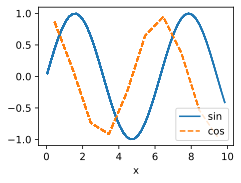

In [29]:
# Import fully impelemtned ProgressBoard from d2l library

# Run again to see "animation"
board = d2l.ProgressBoard('x')
for x in np.arange(0, 10, 0.1):
    board.draw(x, np.sin(x), 'sin', every_n=2)
    board.draw(x, np.cos(x), 'cos', every_n=10)

### 3.2.2 Models

_Module_ class is the base class of all models we will implement. At the very least, we need three methods. 
1. init: Method to store the learnable parameters
2. training_step: This method accepts a data batch to return a loss value
3. configure_optimizers: Method that returns the optimizaiton method, or a list of them that is used to update the learnable parameters. Optionally - we can defined validation_step to report the evaluation measures. Sometimes, we put the code for computing the output into a separate _forward_ method to make it more reusable. 

Notice - _Module_ is a subclass of the _nn.Module_, the base class of neural networks in PyTorch. THis is because it provides convient features for handling neural networks, such as if we define a _forward_ method, such as _forward_(self, X), then for an instance 'a' we can invoke this method by a(x). This is because it calles the _forward_ method in the built-in "call" method (there should be two underscores before and after "call").  

In [30]:
class Module(nn.Module, d2l.HyperParameters): 
    """The base class of models."""
    def __init__(self, plot_train_per_epoch=2, plot_valid_per_epoch=1):
        super().__init__()
        self.save_hyperparameters()
        self.board = ProgressBoard()

    def loss(self, y_hat, y):
        raise NotImplementedError

    def forward(self, X):
        assert hasattr(self, 'net'), 'Neural network is defined'
        return self.net(X)

    def plot(self, key, value, train):
        """Plot a point in animation."""
        assert hasattr(self, 'trainer'), 'Trainer is not inited'
        self.board.xlabel = 'epoch'
        if train:
            x = self.trainer.train_batch_idx / \
                self.trainer.num_train_batches
            n = self.trainer.num_train_batches / \
                self.plot_train_per_epoch
        else:
            x = self.trainer.epoch + 1
            n = self.trainer.num_val_batches / \
                self.plot_valid_per_epoch
        self.board.draw(x, value.to(d2l.cpu()).detach().numpy(),
                        ('train_' if train else 'val_') + key,
                        every_n=int(n))

    def training_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        self.plot('loss', l, train=True)
        return l

    def validation_step(self, batch):
        l = self.loss(self(*batch[:-1]), batch[-1])
        self.plot('loss', l, train=False)

    def configure_optimizers(self):
        raise NotImplementedError

### 3.2.3 Data

_DataModule_ class is the base class for data. Quite frequently, the init method is used to prepare the data, including downloadng and preprocessing if needed. The _train_dataloader_ returns the data loader for the training dataset. 

A data loader is a generator that yields a data batch each time it is used/called. This batch is then fed into the _training_step_ method of _Module_ to compute the loss. There is an optional _val_dataloader_ to return the validation dataset loader. It behaves in the same manner, except it yields data for the _validation_step_ method in _Module_.  

In [31]:
class DataModule(d2l.HyperParameters):  #@save
    """The base class of data."""
    def __init__(self, root='../data', num_workers=4):
        self.save_hyperparameters()

    def get_dataloader(self, train):
        raise NotImplementedError

    def train_dataloader(self):
        return self.get_dataloader(train=True)

    def val_dataloader(self):
        return self.get_dataloader(train=False)

### 3.2.4 Training

The _Trainer_ class train the learnable parameters in the _Module_ class with data specified in _DataModule_. The key method is _fit_, which accepts two arguments: _model_, an instance of _Module_, and _data_, an instance of _DataModule_ It then iterates over the entire dataset _max_epochs_ times to train the model. As the other two before, the full implementation of this will be deferred to later chapters. 

In [32]:
class Trainer(d2l.HyperParameters):  #@save
    """The base class for training models with data."""
    def __init__(self, max_epochs, num_gpus=0, gradient_clip_val=0):
        self.save_hyperparameters()
        assert num_gpus == 0, 'No GPU support yet'

    def prepare_data(self, data):
        self.train_dataloader = data.train_dataloader()
        self.val_dataloader = data.val_dataloader()
        self.num_train_batches = len(self.train_dataloader)
        self.num_val_batches = (len(self.val_dataloader)
                                if self.val_dataloader is not None else 0)

    def prepare_model(self, model):
        model.trainer = self
        model.board.xlim = [0, self.max_epochs]
        self.model = model

    def fit(self, model, data):
        self.prepare_data(data)
        self.prepare_model(model)
        self.optim = model.configure_optimizers()
        self.epoch = 0
        self.train_batch_idx = 0
        self.val_batch_idx = 0
        for self.epoch in range(self.max_epochs):
            self.fit_epoch()

    def fit_epoch(self):
        raise NotImplementedError

### 3.2.5 Summary

### 3.2.6 Exercises
1. Find the full implementations of the classes introduced in this section in the D2L library. Read through them carefully once you are more familiar with deep learning modeling.
2. In class `B`, remove the `save_hyperparameters` statement. Can you still print `self.a` and `self.b`? Optionally, explain why by inspecting the implementation of `HyperParameters`.


Exercise #1

Link to full implementation of classes in D2L Library - PyTorch version. 

https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py

Exercise #2

No, canoot print self.a and self.b anymore, since although they were passed as arguments when initializing the instance of class B as b, they were never passed through and initialized as attribites of the class B or its instance (since that is typically what the save_hyperparameters statement/class should've been doing). Reference the Hyperparameters class, linked above. 

In [33]:
# Copied from earlier with "save_hyperparameters" commented out. 


class B(d2l.HyperParameters):
    def __init__(self, a, b, c):
        # self.save_hyperparameters(ignore=['c'])
        print('self.a = ', self.a, 'self.b = ', self.b)
        print('There is no self.c = ', not hasattr(self, 'c'))

b = B(a = 1, b = 2, c = 3)

AttributeError: 'B' object has no attribute 'a'

# 3.3 Synthetic Regression Dataset

Synthetic data is helpful for educational purposes, since if we create data for which the correct parametrs are known in advance, then we can check if our models are correct/implemented correctly by checking if we can recover them. 

In [34]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l

### 3.3.1 Generating the Dataset

Will be working in low dimensions for succintness. Following code generates 1000 examples with 2-dimensional features drawn from standard normal distribution. Resultant design matrix $X \in \mathbb{R}^{1000 \times 2}$. We generate each lavel by applying a ground truth linear function (and try to recover a linear fit), and then corrupt it by adding additive noise $\epsilon$, drawn from an i.i.d. sample of $\mu = 0$ and $\sigma = 0.01$. 

Note that for object-oriented design, we add the code to the init method fo a subclass of d2l.DataModule. It is good practice to allow the setting of any additional hyperparameters, using the save_hyperparameters(). The _batch_size_ will be determined later. 

In [35]:
class SyntheticRegressionData(d2l.DataModule):  
    """Synthetic data for linear regression."""
    def __init__(self, w, b, noise=0.01, num_train=1000, num_val=1000, batch_size=32):
        super().__init__() # Initialize attributes of parent class (DataModule)
        self.save_hyperparameters()
        n = num_train + num_val
        self.X = torch.randn(n, len(w))    # Randomly generate features of input for design matrix
        noise = torch.randn(n, 1) * noise  # Bias vector
        # reshape( (-1, 1) ) reshapes w from 1D tensor to 2D tensor where the the columns are the same as the 
        # originally specified w tensor, but the rows are now automatically inferred (recall, -1 means 
        # "infer the number of rows based on the number of columns and the total number of elements in the tensor") 
        self.y = torch.matmul(self.X, w.reshape((-1, 1))) + b + noise

In [36]:
# Will be setting true parameters to w = [2, -3.4] and b = 4.2
data = SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)

In [37]:
# Earch row in features consists of a vector in R^2, and each row in labels is a scalar (output/label)
# Look at the first entry of features and labels
print('features:', data.X[0],'\nlabel:', data.y[0])

features: tensor([-0.2200, -2.1577]) 
label: tensor([11.1146])


### 3.3.2 Reading the Dataset

Throughout the iteration below, we obtain distinct minibatches until the entire dataset has been exhausted. While it is good for educational purposes, it is inefficient in that we need to load all the data in memory and we perform lots of random memory access. 

To counter this, the built-in iterators implemented in a deep-learning framework are considerably more efficient and they can deal with sources such as data stores in files, data received via a stream, and data generated or processed on the fly. 

In [38]:
@d2l.add_to_class(SyntheticRegressionData) # Following is the function we will add to the class SyntheticRegressionData  
def get_dataloader(self, train):
    if train:
        indices = list(range(0, self.num_train))
        # self.num_train has been added as attribute of SyntheticRegressionData by the 
        # save_hyperparameters method in the __init__ method of SyntheticRegressionData. 

        # The training examples are read in random order by shuffling indices
        random.shuffle(indices)
    else: # Not training, i.e. validation 
        indices = list(range(self.num_train, self.num_train+self.num_val))
        # Not sure why range is being set fro self.num_train to self.num_train + self.num_val, 
        # but will go with it for now. Just use 0 to self.num_val?

        # NVM probably because design matrix was initialized with n = num_train + num_val, 
        # so need to set range from self.num_train to self.num_train + self.num_val to get 
        # the validation examples.

        # No need to shuffle here (no stochasticity in validation examples)

    # No matter if training or validating, following is the same (since indices are already 
    # shuffled for training and not shuffled for validation)
    # NOTE: self.batch_size has been added as attribute of SyntheticRegressionData by the 
    # save_hyperparameters method in the __init__ method of SyntheticRegressionData.
    # NOTE: Step size of range() is set to self.batch_size, so no overlap between batches
    # NOTE: "yield" not "return", since we want to return a generator that can be iterated 
    # through, not just one batch of data. Using "return" would return one batch of data
    # and exit the function
    for i in range(0, len(indices), self.batch_size):
        batch_indices = torch.tensor(indices[i: i+self.batch_size])
        yield self.X[batch_indices], self.y[batch_indices]

In [39]:
# Inspect the first minibatch of data. 

# Turns "data.train_dataloader()" into an iterable, and then gives what is "next" within said iterable
X, y = next(iter(data.train_dataloader()))
print('X shape:', X.shape, '\ny shape:', y.shape)

X shape: torch.Size([32, 2]) 
y shape: torch.Size([32, 1])


### 3.3.3 Concise Implementation of the Data Loader

Rather than writing out own iterator, we can call the existing API in a framework to laod data. As before, we need a daaset with features X and labels y. Beyond that, we set _batch_size_ in the built-in data loader and let it take care of shuttling examples efficiently. 

This will behave just like the previous one, except it is more efficient underneath and has some additional functinalities. 

In [40]:
@d2l.add_to_class(d2l.DataModule)  # Add following get_tensorloader function to the class DataModule, which is the parent class of SyntheticRegressionData.
def get_tensorloader(self, tensors, train, indices=slice(0, None)):
    # Tensors are a tuple expected to be of the form (self.X, self.y) (i.e. design matrix and targets/labels)
    # "train" would be a boolean for indicating training/validating  

    # https://docs.pytorch.org/docs/2.12/data.html
    # TensorDataset: Dataset wrapping tensors. Each sample will be retrieved by indexing tensors
    # along the first dimension 

    # DataLoader: Represents Python iterable over a dataset with support for 
    # map & iteratble style datasets
    # customizing data loading order
    # automatic batching
    # single and muilti process data loading
    # automatic memory pinning (used to speed up transfer of data from CPU to GPU)

    tensors = tuple(a[indices] for a in tensors)
    dataset = torch.utils.data.TensorDataset(*tensors)
    return torch.utils.data.DataLoader(dataset, self.batch_size, shuffle=train, drop_last=True)

@d2l.add_to_class(SyntheticRegressionData)  # Add following get_dataloader function to the class SyntheticRegressionData, which is a child class of DataModule.
def get_dataloader(self, train):
    i = slice(0, self.num_train) if train else slice(self.num_train, None)
    return self.get_tensorloader((self.X, self.y), train, i)

In [41]:
X, y = next(iter(data.train_dataloader()))
print('X shape:', X.shape, '\ny shape:', y.shape)

X shape: torch.Size([32, 2]) 
y shape: torch.Size([32, 1])


In [42]:
# Example of additional feature
len(data.train_dataloader())

31

### 3.3.4 Summary

### 3.3.5 Exercises
1. What happens when the number of examples is not divisible by the batch size? How can you change this behavior using the framework API?
2. Suppose we want to generate a very large dataset, where both the parameter vector $\mathbf{w}$ and the number of examples `num_examples` are large.
   1. What happens if the full dataset cannot fit in memory?
   2. How could you shuffle data stored on disk efficiently, without too many random reads or writes? Hint: pseudorandom permutation generators can reshuffle data without explicitly storing the full permutation table.
3. Implement a data generator that creates new data on the fly each time the iterator is called.
4. How would you design a random data generator that produces the same data every time it is called?

Exercise #1

Already, the number of training examples (1000) is not divisble by the batch_size (32). Already the PyTorch handles it by making the last batch just of a smaller size. 

You can change in this API by making the drop_last=True as is shown above now. This makes the len(data.train_dataloader()) = 31, (insterad of 32 if we were to set it to False or nothing - default is False)

Exercise #2 

If we cannot hold all the data in memory, have the kernel/controller/API load in minibatches from SSD/Storage (non-RAM memory) where it is already shuffled and start shuttling them over by they are "predicted" to be needed (accounting for transfer time) but be conservative in the predicted time for the previous minibatch to finish, otherwise don't want to overlead the limited RAM. But not too conservative to the point where training time is wasted. 

I think what the hint about the "pseudorandom permutation generator can reshuffle data without explicitly storing the full permutation table" is referring to is maybe we organized the minibatch-ed entire training dataset (without shuffling/randomization yet) be given an naive linear index, but have the pseudorandom permutation generator generate numbers to get which specific minibatch we should load from storage to main memory atm. But then we have an issue of already-generated numbers coming up near the end of the training run. 

Not a perfect/complete answer yet, but moving on for now...

Exercise #3

Generate new synthetic data on the fly, rather than generating and loading all the data into memory at once, and then taking a subset of that. 

Notes: 
- Need a while/for loop get_dataloader(), otherwise will only be generating a new batch once. Test of calling X, y and X2, y2 and setting them equatl to next(iter(dataloader))
- Proper way to test is by using for X, y in iter(data_ex3.train_dataloader()) and printing X, y
- Note, calling X,y = next(iter(data_ex3.train_dataloader())) and then again X2, y2 = next(iter(data_ex3.train_dataloader())) will simply create two different iiterables. 
- To make torch.manual_seed() be valid and thus make the generator generate the SAME data every time it is called, must call it within the loop itself (or alternatively could achieve same affect by putting it within cell of for loop testing consecutive minibatches)

In [43]:
# torch.manual_seed(0)

class SyntheticOnDemandRegressionData(d2l.DataModule):  
    """Synthetic data for linear regression."""
    def __init__(self, w, b, num_train=40, num_val=20, noise=0.01, batch_size=10):
        super().__init__() 
        self.save_hyperparameters()
        # n = num_train + num_val
        # self.X = torch.randn(n, len(w))    
        # noise = torch.randn(n, 1) * noise  
        # self.y = torch.matmul(self.X, w.reshape((-1, 1))) + b + noise

        
    def get_dataloader(self, train):
        # No need for indicies when using on-demand data
        #if train:
        #    indices = list(range(0, self.num_train))
        #    random.shuffle(indices)
        #else: 
        #    indices = list(range(self.num_train, self.num_train+self.num_val))

        num_iter = self.num_train if train else self.num_val

        
        for start in range(0, num_iter, self.batch_size):
            torch.manual_seed(0)
            current_batch_size = min(self.batch_size, num_iter - start)

            X = torch.randn(current_batch_size, len(self.w))
            noise = torch.randn(current_batch_size, 1) * self.noise
            y = torch.matmul(X, self.w.reshape( (-1, 1) )) + self.b + noise
            yield X, y

        # for i in range(0, len(indices), self.batch_size):
        #    batch_indices = torch.tensor(indices[i: i+self.batch_size])
        #    yield self.X[batch_indices], self.y[batch_indices]


# Will be setting true parameters to w = [2, -3.4] and b = 4.2
data_ex3 = SyntheticOnDemandRegressionData(w=torch.tensor([2, -3.4]), b=4.2)

# Each row in features consists of a vector in R^2, and each row in labels is a scalar (output/label)
# Look at the first entry of features and labels

# NOTE: X, y are no longer attributes of the class, so call them directly
print('features:', X[0],'\nlabel:', y[0])



# Inspect the first two minibatches of data. 

# Turns "data_ex3.train_dataloader()" into an iterable, and then gives what is "next" within said iterable
# Note - train_dataloader() method is defined within DataModule class, which just calls the get_dataloader method
# https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py
X, y         = next(iter(data_ex3.train_dataloader()))
print("X:", X, "\ny:", y)
print('X shape:', X.shape, '\ny shape:', y.shape)

X2, y2       = next(iter(data_ex3.train_dataloader()))
print("X, y are the same as X2, y2: ", torch.equal(X, X2) and torch.equal(y, y2))

# Are X2 and X the same?
# Seed seems to matter more
# With while loop and fixed seed: True
# With while loop and no seed:    False
# No while loop and fixed seed:   True
# No while loop and no seed:      False


features: tensor([ 0.0140, -1.2292]) 
label: tensor([8.4001])
X: tensor([[-1.1258, -1.1524],
        [-0.2506, -0.4339],
        [ 0.5988, -1.5551],
        [-0.3414,  1.8530],
        [ 0.4681, -0.1577],
        [ 1.4437,  0.2660],
        [ 1.3894,  1.5863],
        [ 0.9463, -0.8437],
        [ 0.9318,  1.2590],
        [ 2.0050,  0.0537]]) 
y: tensor([[ 5.8574],
        [ 5.1589],
        [10.6887],
        [-2.7684],
        [ 5.6818],
        [ 6.1905],
        [ 1.5871],
        [ 8.9737],
        [ 1.7701],
        [ 8.0193]])
X shape: torch.Size([10, 2]) 
y shape: torch.Size([10, 1])
X, y are the same as X2, y2:  True


In [44]:
# torch.manual_seed(0)

counter = 0
for X, y in iter(data_ex3.train_dataloader()):
    # if counter >= 3:
    #     break
    print(f"X{counter}:", X, f"\ny{counter}:", y)
    counter += 1

X0: tensor([[-1.1258, -1.1524],
        [-0.2506, -0.4339],
        [ 0.5988, -1.5551],
        [-0.3414,  1.8530],
        [ 0.4681, -0.1577],
        [ 1.4437,  0.2660],
        [ 1.3894,  1.5863],
        [ 0.9463, -0.8437],
        [ 0.9318,  1.2590],
        [ 2.0050,  0.0537]]) 
y0: tensor([[ 5.8574],
        [ 5.1589],
        [10.6887],
        [-2.7684],
        [ 5.6818],
        [ 6.1905],
        [ 1.5871],
        [ 8.9737],
        [ 1.7701],
        [ 8.0193]])
X1: tensor([[-1.1258, -1.1524],
        [-0.2506, -0.4339],
        [ 0.5988, -1.5551],
        [-0.3414,  1.8530],
        [ 0.4681, -0.1577],
        [ 1.4437,  0.2660],
        [ 1.3894,  1.5863],
        [ 0.9463, -0.8437],
        [ 0.9318,  1.2590],
        [ 2.0050,  0.0537]]) 
y1: tensor([[ 5.8574],
        [ 5.1589],
        [10.6887],
        [-2.7684],
        [ 5.6818],
        [ 6.1905],
        [ 1.5871],
        [ 8.9737],
        [ 1.7701],
        [ 8.0193]])
X2: tensor([[-1.1258, -1.1524],
      

Exercise #4

See above. Add a torch.manual_seed() line within the while loop itself. 

# 3.4 Linear Regression Implementation from Scratch

Now ready to work with fully functining implementation of linear regression where we will implement the entire method from scratch, including the following:
1. Model
2. Loss Function
3. Minibatch SGD optimizer
4. Training Function (that connects everything)

We will also run the synthetic data generator from 3.3 and apply model on said dataset. 

Primarily for educational purposes, as most things mentioned can be automated by modern deep learning frameworks. 

In [45]:
%matplotlib inline
import torch
from d2l import torch as d2l

### 3.4.1 Defining the Model

In [46]:
class LinearRegressionScratch(d2l.Module):  
    """The linear regression model implemented from scratch."""
    def __init__(self, num_inputs, lr, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        # self.w = torch.zeros((num_inputs, 1), requires_grad=True)
        self.w = torch.normal(0, sigma, (num_inputs, 1), requires_grad=True)
        self.b = torch.zeros(1, requires_grad=True)

    def forward(self, X):
        return torch.matmul(X, self.w) + self.b

    def loss(self, y_hat, y):
        l = (y_hat - y) ** 2 / 2
        return l.mean()

    def configure_optimizers(self):
        """Returns an instance of the SGD
        """
        return SGD([self.w, self.b], self.lr)


### 3.4.2 Defining the Loss Function

Instead, of using "@d2l.add_to_class(LinearRegressionScratch)" decorator, will just add it directly to the class itself. Makes it more readable to me. 

### 3.4.3 Defining the Optimization Algorithm

In [47]:
class SGD(d2l.HyperParameters):  #@save
    """Minibatch stochastic gradient descent."""
    def __init__(self, params, lr):
        self.save_hyperparameters()

    def step(self):
        for param in self.params:
            param -= self.lr * param.grad

    def zero_grad(self):
        """Sets all gradients to zero, which must be run before each backward pass (to reset gradients)
        """
        for param in self.params:
            if param.grad is not None:
                param.grad.zero_()

### 3.4.4 Training

Epoch: Iteration over the entire training daatset
Iteration: Each minibatch over the training dataset

Training Steps
1. Initialize Parameters (w, b)
2. Repeat the following for every iteration across for every epoch(s)
    - Compute gradients
    - Update parameters 

Notice - we are adding the methods to the d2l.Trainer class introduced in 3.2.4. What we are doing here is we want a validation dataset to measure the model quality, so we pass the validation dataloader once in each epoch to measure the model performance. 

In [48]:
@d2l.add_to_class(d2l.Trainer)  
def prepare_batch(self, batch):
    return batch

@d2l.add_to_class(d2l.Trainer)  
# Check line 257 where Trainer is defined for better context: https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py
def fit_epoch(self):
    # model will be later passed as an argument when calling the fit method of Trainer from prepare_model method of Trainer
    self.model.train()
    # Has access to train_dataloader, val_dataloader
    for batch in self.train_dataloader:
        loss = self.model.training_step(self.prepare_batch(batch))
        self.optim.zero_grad() # Sets all gradients to zero b4 each backward pass 
        with torch.no_grad():  # Context-manager that disables gradient calculations (since they have already been calculated earlier)
            loss.backward()    # Propogates error using existing computational graph
            if self.gradient_clip_val > 0:  # To be discussed later
                self.clip_gradients(self.gradient_clip_val, self.model)
            self.optim.step()
        self.train_batch_idx += 1 # Increment train_batch_idx after each batch is processed
    if self.val_dataloader is None:
        return
    # Validation loop (once per epoch)
    self.model.eval() # Set the model to evaluation mode (disables dropout, batch norm, etc.)
    for batch in self.val_dataloader:
        with torch.no_grad(): # Like above, don't track operations inside block   
            self.model.validation_step(self.prepare_batch(batch))
        self.val_batch_idx += 1

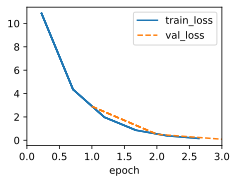

In [49]:
model = LinearRegressionScratch(2, lr=0.03)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=3)
trainer.fit(model, data)

In [51]:
with torch.no_grad():
    print(f'error in estimating w: {data.w - model.w.reshape(data.w.shape)}')
    print(f'error in estimating b: {data.b - model.b}')

error in estimating w: tensor([ 0.2022, -0.2395])
error in estimating b: tensor([0.2937])


In [29]:
# Just curious why the no_grad() context manager was used in above cell. 
# PyTorch by default tracks all operations on tensors that have requires_grad=True, 
# so that it can compute gradients during backpropagation. No backprop, just inspecting here. 

# Q: Difference between SubBackward0 and RsubBackward1?
# A; Used to indicate if said tensor came from standard or reverse subtraction operation  
print(f'error in estimating w: {data.w - model.w.reshape(data.w.shape)}')
print(f'error in estimating b: {data.b - model.b}')

error in estimating w: tensor([ 0.1845, -0.2276], grad_fn=<SubBackward0>)
error in estimating b: tensor([0.2729], grad_fn=<RsubBackward1>)


### 3.4.5 Summary

### 3.4.6 Exercises

1. What happens if the weights are initialized to zero? Would the algorithm still work? What if the parameters are initialized with variance $1000$ instead of $0.01$?
2. Suppose you are Georg Simon Ohm and want to build a model for resistance relating voltage and current. Can automatic differentiation be used to learn the model parameters?
3. Can Planck’s Law be used to determine an object’s temperature from spectral energy density? The spectral density $B$ of radiation from a black body is $B(\lambda, T) = \frac{2hc^2}{\lambda^5} \cdot \left(\exp \frac{hc}{\lambda kT} - 1\right)^{-1}$. Here, $\lambda$ is wavelength, $T$ is temperature, $c$ is the speed of light, $h$ is Planck’s constant, and $k$ is Boltzmann’s constant. Suppose you measure energy at different wavelengths $\lambda$ and need to fit the spectral density curve to Planck’s Law.
4. What problems might occur when computing second derivatives of the loss? How could those problems be fixed?
5. Why is the `reshape` method needed in the `loss` function?
6. Try different learning rates and observe how quickly the loss decreases. Can the error be reduced by increasing the number of training epochs?
7. If the number of examples is not divisible by the batch size, what happens to `data_iter` at the end of an epoch?
8. Try implementing a different loss function, such as absolute value loss: `(y_hat - d2l.reshape(y, y_hat.shape)).abs().sum()`.
    1. Check what happens for regular data.
    2. Check whether behavior changes if some entries are actively perturbed, for example $y_5 = 10000$, in $\mathbf{y}$.
    3. Can you think of an inexpensive way to combine the best aspects of squared loss and absolute value loss? Hint: how can very large gradient values be avoided?
9. Why is reshuffling the dataset necessary? Can you construct a maliciously ordered dataset that would break the optimization algorithm without reshuffling?

Exercise 1

If all the weights were initialized to 0, the algorithim work - just means that the initial loss will the just the target value. After the first backwards pass, it will work the same as before. 

If the parameters were initialized with variance 1000 rather than 0.01, the initial loss would be quite high and convergence would take longer unless the learning rate was adjusted according (static or adaptive). Note that since this is a single linear layer it does not matter much, but in deeper neural networks, a large variance would lead to large parameters, which could lead to the exploding gradient problem. 

Exercise 2

Recall Ohm's Law is: $V=IR$. Automatic differentiation can be used where a linear relationship between I, R and V are assumed. Then, $I$ would be the input and $V$ could be the output, and $R$ could be the learnable parameter that is adjusted based on the gradient resulting from the difference between $\hat{V}$ and $V$ (also include loss function on how to handle difference between $\hat{V}$ and $V$, say MSE)

Exercise 3

Yes, it should be possible. Set the features of the model to be wavelength and the outputs/targets to spectral density. The loss can MSE. Since the problem states "you now now need to fit the spectral density curve to Planck's law", that implies we know the function we are fitting to which makes this essentially a simple, curve-fitting exercise. Unlike before with stock prices, there is no need to force it to logarithim to ensure non-negativity, since assuming the data has been collected properly, the physical world's restraints of non-negativity would already be built in to the data. 

Exercise 4

Some problems that may arise when trying to calculate the 2nd derivative of the loss in ML, is for modern deep neural networks, there are a massive amount of parameters. This, on top of trying to calculate the 2nd derivative is equivalent to calculating the Hessian of the loss (https://arxiv.org/abs/2505.03861), which grows with O(n^2) with parameter count n, unlike the 1st derivative which grows linearly with n. Combined with the large parameter count in modern deep neural networks, it becomes computationally infeasibile due to memory limitations. 

Exercise 5

I am a bit confused about the question here, since it does not seem like the _reshape_ function is within section 3.4 (unless I am blatantly missing something). Looking at the full implementation here (https://github.com/d2l-ai/d2l-en/blob/master/d2l/torch.py), my guess would be to force the shape of the $\hat{y}$ and $y$ to be the same. Recall from earlier, our predictions $\hat{y}$ would have the shape (batch_size, 1), but the labels/counts may just be (batch_size), and the tensors should have the same sizes for additive operations to calculate the loss (maybe, idk because broadcasting is a thing. Probably to ensure safety or to know absolutely confirm what the dimensions are going to be). 

Exercise 6



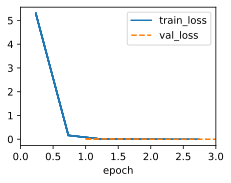

In [30]:
# Much higher learning rate. Convergence much faster. IDT thats necessarily a good thing as 
# generally, that increases the possibility of overshooting and bouncing around near a minima 
# rather than actually descending towards it. 
model = LinearRegressionScratch(2, lr=0.1)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=3)
trainer.fit(model, data)

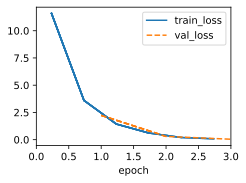

In [31]:
# Same learning rate as before. Just copied and pasted from above for convience. 
model = LinearRegressionScratch(2, lr=0.03)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=3)
trainer.fit(model, data)

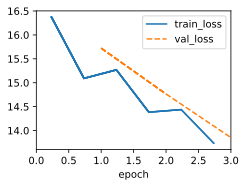

In [32]:
# Much smaller learning rate. Convergence is much slower. Makes sense. 
model = LinearRegressionScratch(2, lr=0.001)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=3)
trainer.fit(model, data)

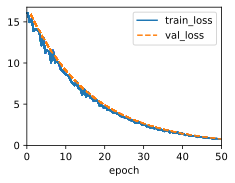

In [33]:
# Much smaller learning rate of 0.001, but much more epochs 
# Takes much longer to converge with the small learning rate, but the larger number of 
# epochs allows it to eventually converge.
model = LinearRegressionScratch(2, lr=0.001)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=50)
trainer.fit(model, data)

Exercise 7

In this case, if the number of total training examples cannot be divided perfectly by the batch size, then the final data_iter would just be the remainder. The data loader here is the SyntheticRegressionData defined earlier in the previous sectino which inherits from DataModule, where the default behavior is to handle the iteration with just a smaller batch size (if it dosen't perfectly divide). 

Exercise 8

Skipping the implementation of a different loss function. 

As for the part about something that combines best aspects of absolute and mean-squared loss with the given hint on how to avoid large gradients. Im guessing a naive version would be to set the magnitude of the loss as a hyperparameter where if the loss is larger than this, use absolute loss and if it is smaller than said hyperparameter, use MSE. IDT this is talking about cross entropy...

Exercise 9

We need to shuffle the dataset to randomize the order of the training examples, since Im guessing overall it would help the model generalize better, as then each mini-batch would be a a best-attempt at a stochastic representation of the entire training set, instead of just focused on a single "type" of training data. 

A maliciously constructed dataset might be a dataset of images where all the dogs are first, followed by all the cats, etc. In this case, without shuffling, the model would first learn representation of dogs, but then have then slowly be overwritten by other examples, with cats following the same trend. 

# 3.5 Concise Implementation of Linear Regression

This section will just show how to implement the things done in previous section (that were done "manually") automatically using the modern high-level API. 

Note - a "fully connected" layer is just a single-layer linear neural network. I think a typical "fully connected" layer would also cover/include activation functions asw.

In PyTorch, a fully connected layer is defined in _Linear_ and _LazyLinear_ classes. _LazyLinear_ allows the user to only define the output dimension, while _Linear_ asks how many inputs go into said layer. Since specifying input shapes is inconvenient and may require non-trivial calculations (such as in convolutional layer). Thus, _LazyLinear_ classes are preferred for the most part. 

In [34]:
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l

### 3.5.1 Defining the Model

In [35]:
class LinearRegression(d2l.Module):  
    """The linear regression model implemented with high-level APIs."""
    def __init__(self, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.LazyLinear(1)
        self.net.weight.data.normal_(0, 0.01)
        self.net.bias.data.fill_(0)

    def forward(self, X):
        return self.net(X)
    
    def loss(self, y_hat, y):
        fn = nn.MSELoss()
        return fn(y_hat, y)

    def configure_optimizers(self):
        return torch.optim.SGD(self.parameters(), self.lr)

    def get_w_b(self):
        return (self.net.weight.data, self.net.bias.data)

### 3.5.2 Defining the Loss Function

Added directly to the LinearRegression class above. I get how the add_to_class decorator works, but havng everything in one place helps readability. 

### 3.5.3 Defining the Optimization Algorithm

Added directly to the LinearRegression class above. I get how the add_to_class decorator works, but havng everything in one place helps readability. 

### 3.5.4 Training

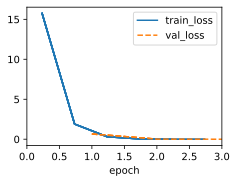

In [36]:
model = LinearRegression(lr=0.03)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=3)
trainer.fit(model, data)

In [37]:
w, b = model.get_w_b()

print(f'error in estimating w: {data.w - w.reshape(data.w.shape)}')
print(f'error in estimating b: {data.b - b}')

error in estimating w: tensor([ 0.0062, -0.0101])
error in estimating b: tensor([0.0113])


### 3.5.5 Summary

There are many modern deep learning frameworks such as MXnet, JAX, PyTorch, and TensorFlow. We can use such frameworks for (1) loading data, (2) defining a layer, (3) a loss function, (4) an optimizer and training loop. 

Whenever the framework provides all necessary features, it is generally a good idea to use them, since the library implementations of these components tend to be heavily optimized for performance and properly tested for reliability. At the same time, keep in mind that these modules can be implemented directly - especially important for researchers who are involved in model development at the leading edge where you would have to invent new components/building-blocks that do not exist yet in any current library. 

I think (not absolutely sure yet), but PyTorch should be able to support new neural network building blocks... (e.g. scaled dot product attention, just might be unoptimized due to lack of hardware level support, I think...)

### 3.5.6 Exercises
1. If the aggregate loss over a minibatch is replaced by the average minibatch loss, how should the learning rate be changed?
2. Check the framework documentation for available loss functions. Replace squared loss with Huber's robust loss:
   $$l(y,y') = \begin{cases}|y-y'|-\frac{\sigma}{2}, & \textrm{if } |y-y'| > \sigma \\ \frac{1}{2\sigma}(y-y')^2, & \textrm{otherwise}\end{cases}$$
3. How can you access the gradient of the model weights?
4. What happens to the solution when you vary the learning rate and number of epochs? Does the solution keep improving indefinitely?
5. How does the solution change as the amount of generated data varies?
   1. Plot the estimation errors $\hat{\mathbf{w}}-\mathbf{w}$ and $\hat{b}-b$ as functions of the amount of data. Hint: increase data size logarithmically, e.g., $5, 10, 20, 50, \ldots, 10000$.
   2. Why is logarithmic scaling appropriate here

Exercise #1

If we replace aggregate loss over a minibatch by the average minibatch, since we should increase the learning rate by a multiple corresponding to the size of the minibatch (since that is demoninator in the parameter updates), since this change will result in a smaller magnitude update to each parameter. 

Exercise #2

Use torch.nn.HuberLoss OR torch.nn.functional.huber_loss
Note, the former is a object-oriented class that inherits from the nn.Module class, but the latter is a stateless function. Choose accordingly...

Refer: 
https://docs.pytorch.org/docs/2.12/generated/torch.nn.HuberLoss.html
https://docs.pytorch.org/docs/2.12/generated/torch.nn.functional.huber_loss.html

Exercise #3

To see the gradient of the model weights, can refer to them either by index of layers in the model, or call them directly by name:

* print(model[0].weight.grad)
* print(model.my_layer.weight.grad)

Exercise #4 

Effect of varying learning rate and # of epochs is intuitive and shown in earlier cells/sections. 

The solution does not improve indefinitely, as it is restricted by "0 loss". Note that even "0-loss" on the training set may not be particularly desirable especailly if the scores on the validation set stop improving while the training loss keeps going down - which indicates overfitting. 

Exercise #5

For larger datasets, 

In [ ]:
# Reference from Earlier
model = LinearRegression(lr=0.03)
data = d2l.SyntheticRegressionData(w=torch.tensor([2, -3.4]), b=4.2)
trainer = d2l.Trainer(max_epochs=3)
trainer.fit(model, data)

w, b = model.get_w_b()

print(f'error in estimating w: {data.w - w.reshape(data.w.shape)}')
print(f'error in estimating b: {data.b - b}')

num_train = 10000
  w1 error:  0.000658
  w2 error:  0.000230
  b  error:  0.000086



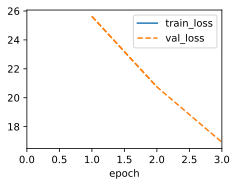

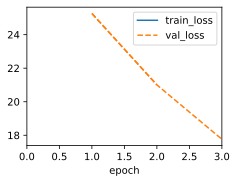

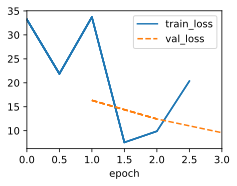

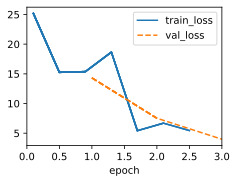

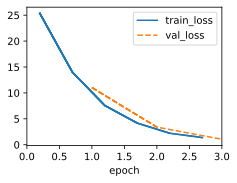

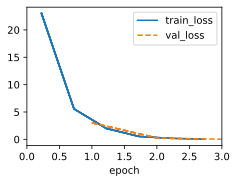

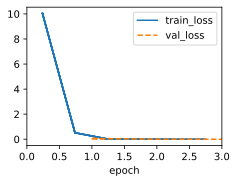

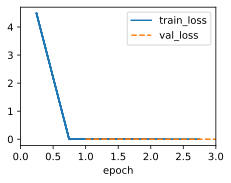

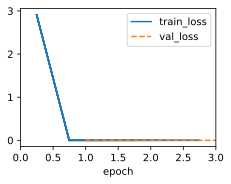

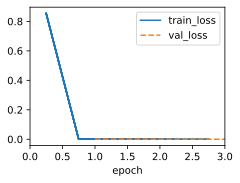

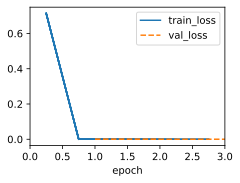

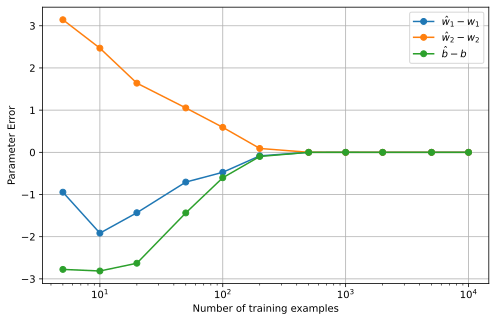

In [ ]:
import matplotlib.pyplot as plt

def VaryDatasetSize(dataset_sizes=[5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000],
                    lr=0.03,
                    max_epochs=3,
                    batch_size=10,
                    true_w=torch.tensor([2, -3.4]),
                    true_b=4.2):
    
    w1_errors = []
    w2_errors = []
    b_errors = []

    for dataset_size in dataset_sizes:
        model = LinearRegression(lr=lr)

        data = d2l.SyntheticRegressionData(
            w=true_w,
            b=true_b,
            num_train=dataset_size,
            num_val=200,
            batch_size=batch_size
        )

        trainer = d2l.Trainer(max_epochs=max_epochs)
        trainer.fit(model, data)

        w_hat, b_hat = model.get_w_b()

        w_error = w_hat.reshape(data.w.shape) - data.w
        b_error = b_hat - data.b

        w1_errors.append(w_error[0].item())
        w2_errors.append(w_error[1].item())
        b_errors.append(b_error.item())

        print(f"num_train = {dataset_size}")
        print(f"  w1 error: {w_error[0].item(): .5f}")
        print(f"  w2 error: {w_error[1].item(): .5f}")
        print(f"  b  error: {b_error.item(): .5f}")
        print()

    return data_sizes, w1_errors, w2_errors, b_errors

data_sizes, w1_errors, w2_errors, b_errors = VaryDatasetSize()


plt.figure(figsize=(8, 5))

plt.plot(data_sizes, w1_errors, marker='o', label=r'$\hat{w}_1 - w_1$')
plt.plot(data_sizes, w2_errors, marker='o', label=r'$\hat{w}_2 - w_2$')
plt.plot(data_sizes, b_errors, marker='o', label=r'$\hat{b} - b$')

plt.xscale('log')
plt.xlabel('Number of training examples')
plt.ylabel('Parameter Error')
plt.legend()
plt.grid(True)
plt.show()

# 3.6 Generalization

Techniques to combatting overfitting are called _regularization_. No substitute for proper understandng fo statistical learning theory, but D2L says they will give just enough intuition to get going. Saved the 2 textbooks reccomended by D2L in tracker Word file. Will cover what is known about principles underlying generalization in various models, and also heuristic techniques that have empirically been found to yield improved generalizaton on tasks of practical interest. 

### 3.6.1 Training Error and Generalization Error

In standard supervised learning setting, we assume that training & test data are drawn _independently_ from _identitcal_ distributions, which is called the _IID assumption_. Note that this is a strong assumption, but without it one is stuck. Typically there would be no reason to believe training data sampled from distribution $P(X, Y)$ should help us generate predictions about data generated from a different distribution $Q(X, Y)$. If we were to do so, that would require some strong assumoptions about how $P$ and $Q$ are related. Later, we will discuss some assumoptions that allow for shifts in distribution fir first need to understand the IID case (i.e. $P(X, Y) = Q(X, Y)$). 

* $R_{emp}: _Training Error_, which is a _statistic_ calculated on the training dataset. It is formally expressed as the following: 
$$ R_{emp}[X, y, f] = \frac{1}{n}\sum_{i=1}^n l(x^{(i)}, y^{(i)}, f(x^{(i)}))$$
* $R$: _Generalization Error_, which is an _expectation_ taken with respect to the underlying distribution. Can think of this as what you would see if you applied model to an infinite stream of additional data examples drawn from same underlying data distribution. It is formally expressed as the following: 
$$ R[p, f] = E_{(x, y)} \sim P [l(x, y, f(x))] = \int \int l(x, y, f(x))p(x, y) dxdy$$

We can never know the generalization error $R$ exactly since we don't ahve access to $p(x, y)$, and we also can't realistically sample an infinite stream of data points, which is a problem. Thus, we must estimate the generalization error by applying our model to an independent test set consisting of a random selection of examples $X'$ and labels $y'$ that were withheld from our training set. This consists of applying the same formula that was used for calculating the empirical training error $R_{emp}$ but to a test set $X', y'$. 

The central quesiton of generalization is when we expect our training error to be close to the population error (and thus the generalization error). 

### 3.6.1.1 Model Complexity

In classical theory when we have simple models and abundant data, the training and generalization errors tend to be close. However, when we work with more complex models and/or fewer training examples, we expect the training error to go down but the generalizatino gap to grow, since the model can better fit the training data, and avoid learning generalizable patterns. \

In general, absent of any restriction on our model size, we cannot conclude that based on fitting the training data along, that our model ahs discovered any generalizable pattern. OTOH, if our model class was not capable of fitting arbitary labels, then it must have discovered a pattern. 

How to measure a model's complexity? Usually, models with more parameters are able to fit a greater number of arbitrarily assigned labels. Some exceptions to this are kernel methods which operate in spaces with infinite number of parameters, yet their complexity is controlled by other means. 

Another measure of complexity is the range of values a parameter can take - a model whose parameters are allows to take any arbitary value would be more complex. This will be investigated in more detail in the next section about weight decay. 

Takeaway: Low training error does not imply low generealization error, nor does it imply high generalization error. Only thing 4 sure is low training error alone is not enough to assert low generelization error. For DNNs we should rely on holdout data i.e. validation set to get the _validation error_. 

### 3.6.2 Underfitting or Overfitting?

Firstly, we want to avoid situations where both training & validation error are both substantial but there is little difference between the two. This implies that the model is too simple and unable to reduce the training error. Additionally, since the generelizatino gap is small, this implies that we can get away with a more complex model. This phenomenon is known as _underfitting_. 

OTOH, we also want to avoid situations where training error is significantly lower than the validation error. This implies _overfitting_. Note, overfitting is not always a bad thing since with DNN's, the best predictive models often perform better on training than validation data. 

There's also stuff about polynomial curve fitting, which I will skip. Takeaway is for 1-dimensional data, if a polynomial has as many parameters/degrees as there are datapoints, it can fit the data perfectly, but that would be blatant overfitting. However, it would result in horrible generalization. 

Final stuff about dataset size - generelization error usually decreases with more data. For a given task and data distribution, the model complexity should not increase more rapidly than the amount of data (to prevent overfitting). Note, deep learning only outperforms linear models when many thousands of training examples are available. 

### 3.6.3 Model Selection

Typically select the final model only after evaluating multiple models that differ in vary ways such as:
* Different architectures
* Training objectives
* Selected features
* Data preprocessing
* Learning rates

In Principle, we should not touch the test set until after all design considerations and hyperparameter tweaking, etc. This is to avoid fitting the model to it - as if we fit the model to training data, hopefully the test set is an indicator of such. But if we were to train model on entire available data, then how would we ever know if we overfit to training set? - we dont. Hence why it exists. 

Common practice to avoid _training on the test set_ is to split our data in three ways, training set, test set, and the validation set. For the rest of of the book (unless explicitly stated otherwise), experiments we are workng with will be training and validation sets only - with no true test sets. 

### 3.6.3.1 Cross-Validation

When training data is scarse, we may not be afford to set aside enough data to form a proper validation set. In this case, it is possible to employ a K-fold _cross-validation_ where the original training data is split into K non-overlapping subsets. Then, the model is trained and validated K times, where each time it is trained on K-1 of the subsets and validated on the final one. The final training and validation errors are estimated by averaging the results over K experiments. 

### 3.6.4 Summary

Some rules of thumb:
1. Use validation sets (or K-fold cross validations if limited dataset size) for model selection
2. More complex models often require more data
3. Complexity for a model can be measured in # of parameters, and range allowed for said parameters
4. All else equal, more data leads to better generalization
5. Generalization is build on IID assumoption. If we drop said assumoptio nand allow for distributional shifts between train & test periods, we cannot comment on generalization (barring further, milder assumoptions)

### 3.6.5 Exercises
1. When can you solve the problem of polynomial regression exactly?
2. Give at least five examples where dependent random variables make treating the problem as IID data inadvisable.
3. Can you ever expect to see zero training error? Under which circumstances would you see zero generalization error?
4. Why is $K$-fold cross-validation very expensive to compute?
5. Why is the $K$-fold cross-validation error estimate biased?
6. The VC dimension is defined as the maximum number of points that can be classified with arbitrary labels ${\pm 1}$ by a function of a class of functions. Why might this not be a good idea for measuring how complex the class of functions is? Hint: consider the magnitude of the functions. 
7. Your manager gives you a difficult dataset on which your current algorithim does not perform so well. How could you justify to him that you need more data? Hint: you cannot increase the data but you can decrease it.

Exercise #1

Polynomial regression can be solved exactly when there are as many coefficients that is the same as the number of unique data points

Exercise #2

Five examples where dependence among random variables that makes IID assumption innappropriate. 
1. Time-dependence (i.e. stock prices)
2. Spatial-dependence (i.e. traffic accidents due to local infrastructure)
3. Group-dependence (i.e. products from same factory)

(googled/gemini'ed the following 2)
4. Social/Network Dependence
5. Repeated measurements from same subject

Exercise #3

Yes, it is possible to see zero training error, typically when the model is much more complex than "necessary" to generalize from training set in question, which qould result in overfitting/perfectly-fitting the data. 

Zero generalization error would be seen when the empirical risk is the exactly the same as the true/test risk. This would indicate that the training set is a perfect representation of the underlying "true" data distribution/generating-process. 

Exercise #4

K-fold cross-validation is very expensive since one must train and validate the same model K-times. 

Exercise #5

The K-fold cross-validation estimate is baised because each of the K runs only trains aon K-1 folds of the total training set, hence the bias in each training run that is hopefully reduced by averaging it out. 

Exercise #6 

Not sure about this - and IDT its worth spending time on, but my guess is: Dosen't distinguish between large magnitudes and small magnitudes, so messes up stability or confidence of a models predictions (over the incorrect answers, ... idk)

Exercise #7

Maybe use smaller subsets of the dataset as a training set for each experiment. Thus, if I can show that the training and validation loss increase as the dataset gets smaller, perhaps this can serve as justification for going out and getting a larger dataset. This of course assume algorithim/architectural design choices are not the "true" issue here. 

# 3.7 Weight Decay

In [2]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l

### 3.7.1 Norms and Weight Decay

Rather than directly manipulating the number of parameters, _weight decay_ operators by restricting values the parameters can take. The motivation/intuition behind them is as follows - among all possible functions, the function $f=0$ is the "simplest" and that we can measure the complexity of a function by the distance of its parameters from zero. Apparently, not a single precise answer for this, apparently stuff like functional analysis & theory of Banach spaces can be used to answer this (dosen't seem like something for me to look into).

One simple way to measure complexity of linear function $f(x) = w^\top x$ is its norm of its weight vector, $||w||^2$. We ensure a small weight vector by adding its norm as a penalty term within the loss/objective function. However, we also need to be careful since if we naively add the norm of the weight to the MSE loss term, the optimizer might just end up minimizng the parameter magnitudes rather than minimizng the prediction loss, so we weight the norm of the weights by a _regularization constant_ $\lambda$ (we will also add a $\frac{1}{2}$) constant so the derivative of the term will be "cleaner". Note, we will also use the norm-squared ($||w||^2$), not the norm ($||w||$) for computational convience asw (when taking derivative). 

Why the $\ell_2$ and not the $\ell_1$? Punished larger "misses" harsher than $\ell_1$, thus distributing the weight more evenly across a larger number of features. OTOH, $\ell_1$ regularization leads to models concentrating weights on a smaller set of features (apparently this is where "feature selection" comes into play, if we want to rely on a few features or not. probably will make more sense later)

This gives us an new loss/objective function of: 
$$ L(w, b) = \frac{1}{n}\sum_{i=1}^n \frac{1}{2} \left(w^\top x^{(i)} + b -y^{(i)} \right)^2 + \frac{\lambda}{2} ||w||^2$$

This gives us SGD updates of: 
$$ w \leftarrow (1- \eta \lambda)w - \frac{\eta}{|\Beta|}\sum_{i\in \beta} x^{(i)} \left(w^\top x^{(i)} + b - y^{(i)}\right)$$

Notice that we still update $w$ based on the prediction difference/loss, but we also _decay_ the weight at each backwards pass. 

### 3.7.2 High-Dimensional Linear Regression

Simple synthetic example that will have data generated from: 

$ y = 0.05 + \sum_{i=1}^{d} 0.01x_i + \epsilon $ where $\epsilon \sim \mathcal{N}(0, 0.01^2)$

We will make overfitting more pronounced by increasing dimensionality of problem to $d=200$ and work with a small training set of only $20$ examples. 

In [3]:
class Data(d2l.DataModule):
    def __init__(self, num_train, num_val, num_inputs, batch_size):
        self.save_hyperparameters()
        n = num_train + num_val
        self.X = torch.randn(n, num_inputs)
        noise = torch.randn(n, 1) * 0.01
        w, b = torch.ones((num_inputs, 1)) * 0.01, 0.05
        self.y = torch.matmul(self.X, w) + b + noise

    def get_dataloader(self, train):
        i = slice(0, self.num_train) if train else slice(self.num_train, None)
        return self.get_tensorloader([self.X, self.y], train, i)

### 3.7.3 Implementation from Scratch

Since minimatch SGD is our optimizer, just need to add the weight decay $\ell_2$ regularization penality to the loss function. THe most conviennent, straightforward way to do this would be to square all the terms in place and sum them (recall it is norm-squared for computational convience - just adjust regularization constant $\lambda$ accordingly). 

In [ ]:
def l2_penalty(w):
    return (w ** 2).sum() / 2

class WeightDecayScratch(d2l.LinearRegressionScratch):
    def __init__(self, num_inputs, lambd, lr, sigma=0.01):
        super().__init__(num_inputs, lr, sigma)
        self.save_hyperparameters()

    def loss(self, y_hat, y):
        return (super().loss(y_hat, y) +
                self.lambd * l2_penalty(self.w))

# Hyperparameters and dataset sizes chosen to induce blatant overfitting
data = Data(num_train=20, num_val=100, num_inputs=200, batch_size=5)
trainer = d2l.Trainer(max_epochs=10)

def train_scratch(lambd):
    model = WeightDecayScratch(num_inputs=200, lambd=lambd, lr=0.01)
    model.board.yscale='log'
    trainer.fit(model, data)
    print('L2 norm of w:', float(l2_penalty(model.w)))

L2 norm of w: 0.010178990662097931


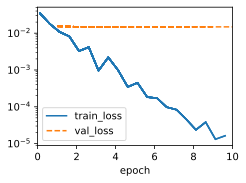

In [6]:
# Train WITHOUT regularization (i.e. lambda = 0)
# See how the training loss keeps decreasing, but the validation loss does not - textbook overfitting
train_scratch(0)

L2 norm of w: 0.0017735098954290152


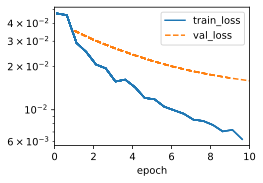

In [7]:
# Validation loss is higher than training loss, but both are decreasing (unlike before)
train_scratch(3)

### 3.7.4 Concise Implementation

Due to popualrity of weight decay in training deep neural networks, modern deep learning frameworks already have it built in. 

In our case, need tro specify regularization term through weight decay when calling optimizer. By default, PyTorch decays both weights & biases, but we can set them differently if desired. 

In the following, only weight decay is enabled for the weights, and the bias terms will not decay. 

In the remaining chapters, the common rule-of-thumb of weight decay will be applied to all layers of a deep network

L2 norm of w: 0.014941353350877762


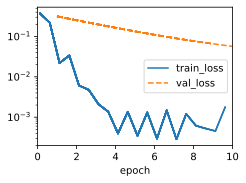

In [10]:
class WeightDecay(d2l.LinearRegression):
    def __init__(self, wd, lr):
        super().__init__(lr)
        self.save_hyperparameters()
        self.wd = wd

    def configure_optimizers(self):
        return torch.optim.SGD([
            {'params': self.net.weight, 'weight_decay': self.wd},
            {'params': self.net.bias}], lr=self.lr)
    
    
model = WeightDecay(wd=3, lr=0.01)
model.board.yscale='log'
trainer.fit(model, data)

print('L2 norm of w:', float(l2_penalty(model.get_w_b()[0])))

### 3.7.5 Summary

### 3.7.6 Exercises
1. Experiment with different values of $\lambda$ in the estimation problem from this section. Plot training and validation accuracy as functions of $\lambda$. What do you observe?
2. Use a validation set to choose the best value of $\lambda$. Is this value truly optimal? Does that matter?
3. If the penalty is changed from $\|\mathbf{w}\|^2$ to $\sum_i |w_i|$, corresponding to $\ell_1$ regularization, what do the update equations look like?
4. Since $\|\mathbf{w}\|^2 = \mathbf{w}^\top \mathbf{w}$ for vectors, find the analogous expression for matrices using the Frobenius norm.
5. Review the relationship between training error and generalization error. Besides weight decay, more training data, and choosing an appropriate model complexity, what other methods can help address overfitting?
6. In Bayesian statistics, the posterior satisfies $P(w \mid x) \propto P(x \mid w)P(w)$. How can the prior $P(w)$ be interpreted as regularization?